# 1. Installation

In [1]:
# ==============================
# INSTALLATION — backend ONNX sans TensorFlow
# ==============================
!pip install insightface --quiet
!pip install onnxruntime-gpu --quiet
!pip install opencv-python-headless --quiet

print("Installation terminée ✅")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 762.2/762.2 kB 10.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 91.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 277.0/277.0 MB 6.7 MB/s eta 0:00:00:00:0100:01
Installation terminée ✅


# 2. Imports et configuration

In [2]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
import warnings
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")

# ==============================
# CHEMINS
# ==============================
MODEL_PATH   = "/kaggle/input/datasets/imaneougni/mtl-last-best-model/best_model_ft (4).pth"
DATASET_PATH = "/kaggle/input/datasets/imaneougni/dataset-faces-detection"
OUTPUT_PATH  = "/kaggle/working/pipeline_results"

os.makedirs(OUTPUT_PATH, exist_ok=True)

# ==============================
# CONSTANTES
# ==============================
IMG_SIZE = 112
AGE_MAX  = 100.0

GENDER_LABELS  = {0: "Homme", 1: "Femme"}
EMOTION_LABELS = {
    0: "Surprise",
    1: "Peur",
    2: "Dégoût",
    3: "Joie",
    4: "Tristesse",
    5: "Colère",
    6: "Neutre",
}
EMOTION_COLORS = {
    0: (83,  74,  183),   # Surprise  — violet
    1: (55, 138, 221),    # Peur      — bleu
    2: (212, 83, 126),    # Dégoût    — rose
    3: (239, 159,  39),   # Joie      — orange
    4: ( 29, 158, 117),   # Tristesse — vert
    5: (226,  75,  74),   # Colère    — rouge
    6: (136, 135, 128),   # Neutre    — gris
}

print(f"Model path   : {MODEL_PATH}")
print(f"Dataset path : {DATASET_PATH}")
print(f"Output path  : {OUTPUT_PATH}")

Device : cuda
Model path   : /kaggle/input/datasets/imaneougni/mtl-last-best-model/best_model_ft (4).pth
Dataset path : /kaggle/input/datasets/imaneougni/dataset-faces-detection
Output path  : /kaggle/working/pipeline_results


# 3. Définition de l'architecture MTL

In [3]:
# ==============================
# ARCHITECTURE MTLFaceModel
# Doit être identique à celle utilisée pour l'entraînement
# ==============================
class MTLFaceModel(nn.Module):
    def __init__(self, freeze_backbone=False):
        super(MTLFaceModel, self).__init__()

        resnet = models.resnet50(weights=None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

        # Tête Genre
        self.head_gender = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(2048, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 2)
        )

        # Tête Âge
        self.head_age = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # Tête Émotion
        self.head_emotion = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(512, 7)
        )

    def forward(self, x):
        features    = self.backbone(x).flatten(1)
        out_gender  = self.head_gender(features)
        out_age     = self.head_age(features)
        out_emotion = self.head_emotion(features)
        return out_gender, out_age, out_emotion


print("Architecture MTLFaceModel définie ✅")

Architecture MTLFaceModel définie ✅


# 4. Chargement du modèle MTL

In [4]:
# ==============================
# CHARGEMENT DU MODÈLE MTL
# ==============================
model = MTLFaceModel(freeze_backbone=False).to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device)
)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"Modèle chargé ✅")
print(f"  Paramètres totaux : {total_params:,}")
print(f"  Device            : {device}")

# Test forward pass
dummy = torch.randn(1, 3, 112, 112).to(device)
with torch.no_grad():
    og, oa, oe = model(dummy)
print(f"  Forward pass OK   : genre={og.shape} âge={oa.shape} émotion={oe.shape}")

Modèle chargé ✅
  Paramètres totaux : 26,203,466
  Device            : cuda
  Forward pass OK   : genre=torch.Size([1, 2]) âge=torch.Size([1, 1]) émotion=torch.Size([1, 7])


# 5. Chargement RetinaFace

In [5]:
# ==============================
# CHARGEMENT RETINAFACE via insightface
# Backend ONNX — pas de TensorFlow
# ==============================
from insightface.app import FaceAnalysis
from insightface.model_zoo import model_zoo

# Initialisation avec seulement le détecteur (pas de recognition)
face_app = FaceAnalysis(
    name       = "buffalo_sc",     # modèle léger : détection + landmarks
    providers  = ["CUDAExecutionProvider", "CPUExecutionProvider"],
    allowed_modules = ["detection"]
)
face_app.prepare(ctx_id=0, det_size=(640, 640), det_thresh=0.5)

print("RetinaFace (insightface) chargé ✅")
print("  Backend    : ONNX — pas de TensorFlow")
print("  Modèle     : buffalo_sc (detection)")
print("  Landmarks  : 5 points")

# Test warm-up
import numpy as np
dummy_img = np.zeros((112, 112, 3), dtype=np.uint8)
_ = face_app.get(dummy_img)
print("  Warm-up effectué ✅")

download_path: /root/.insightface/models/buffalo_sc


100%|██████████| 14619/14619 [00:00<00:00, 83343.12KB/s]


Applied providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CUDAExecutionProvider': {'sdpa_kernel': '0', 'use_tf32': '1', 'fuse_conv_bias': '0', 'prefer_nhwc': '0', 'tunable_op_max_tuning_duration_ms': '0', 'enable_skip_layer_norm_strict_mode': '0', 'tunable_op_tuning_enable': '0', 'tunable_op_enable': '0', 'use_ep_level_unified_stream': '0', 'device_id': '0', 'has_user_compute_stream': '0', 'gpu_external_empty_cache': '0', 'cudnn_conv_algo_search': 'EXHAUSTIVE', 'cudnn_conv1d_pad_to_nc1d': '0', 'gpu_mem_limit': '18446744073709551615', 'gpu_external_alloc': '0', 'gpu_external_free': '0', 'arena_extend_strategy': 'kNextPowerOfTwo', 'do_copy_in_default_stream': '1', 'enable_cuda_graph': '0', 'user_compute_stream': '0', 'cudnn_conv_use_max_workspace': '1'}}
find model: /root/.insightface/models/buffalo_sc/det_500m.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'], with opti

# 6. Transform pour le modèle MTL

In [6]:
# ==============================
# TRANSFORM — identique à val_test_transform de l'entraînement
# ==============================
mtl_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    ),
])

print("Transform défini ✅")
print(f"  Resize     : {IMG_SIZE}×{IMG_SIZE}")
print(f"  Normalize  : mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]")

Transform défini ✅
  Resize     : 112×112
  Normalize  : mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]


# 7. Fonction d'alignement facial

In [7]:
# ==============================
# ALIGNEMENT FACIAL
# Utilise les 5 landmarks pour redresser le visage
# ==============================
def align_face(img_rgb, landmarks, output_size=112):
    """
    Aligne le visage en utilisant les 5 landmarks RetinaFace.
    Applique une transformation affine pour centrer et redresser.

    Paramètres
    ----------
    img_rgb    : image numpy RGB
    landmarks  : dict avec keys right_eye, left_eye, nose,
                 mouth_right, mouth_left — coordonnées [x, y]
    output_size: taille de sortie (112)

    Retourne
    --------
    face_aligned : patch facial aligné (output_size × output_size, RGB)
    """
    # Points de référence cibles (standard pour 112×112)
    dst_pts = np.array([
        [38.2946, 51.6963],   # œil droit
        [73.5318, 51.5014],   # œil gauche
        [56.0252, 71.7366],   # nez
        [41.5493, 92.3655],   # bouche droite
        [70.7299, 92.2041],   # bouche gauche
    ], dtype=np.float32)

    # Points sources depuis RetinaFace
    src_pts = np.array([
        landmarks["right_eye"],
        landmarks["left_eye"],
        landmarks["nose"],
        landmarks["mouth_right"],
        landmarks["mouth_left"],
    ], dtype=np.float32)

    # Transformation affine (similitude) — rotation + scale + translation
    tform, _ = cv2.estimateAffinePartial2D(
        src_pts, dst_pts,
        method=cv2.LMEDS
    )

    if tform is None:
        # Fallback : crop simple sans alignement
        return None

    face_aligned = cv2.warpAffine(
        img_rgb, tform,
        (output_size, output_size),
        flags      = cv2.INTER_LINEAR,
        borderMode = cv2.BORDER_CONSTANT,
        borderValue= (0, 0, 0)
    )

    return face_aligned


print("Fonction d'alignement facial définie ✅")

Fonction d'alignement facial définie ✅


# 8. Fonction de prédiction MTL

In [8]:
# ==============================
# PRÉDICTION MTL SUR UN PATCH FACIAL
# ==============================
def predict_face(face_rgb):
    """
    Prédit genre, âge et émotion depuis un patch facial RGB.

    Paramètres
    ----------
    face_rgb : numpy array RGB (n'importe quelle taille)

    Retourne
    --------
    dict avec gender_label, gender_conf, age, emotion_label,
              emotion_conf, emotion_id
    """
    # Prétraitement
    pil_img = Image.fromarray(face_rgb)
    tensor  = mtl_transform(pil_img).unsqueeze(0).to(device)

    with torch.no_grad():
        out_g, out_a, out_e = model(tensor)

    # Genre
    probs_g      = torch.softmax(out_g, dim=1)[0]
    gender_id    = int(probs_g.argmax().item())
    gender_conf  = float(probs_g[gender_id].item())
    gender_label = GENDER_LABELS[gender_id]

    # Âge (dénormalisation)
    age_norm = float(out_a.squeeze().item())
    age      = round(age_norm * AGE_MAX)
    age      = max(1, min(100, age))   # clamp [1, 100]

    # Émotion
    probs_e       = torch.softmax(out_e, dim=1)[0]
    emotion_id    = int(probs_e.argmax().item())
    emotion_conf  = float(probs_e[emotion_id].item())
    emotion_label = EMOTION_LABELS[emotion_id]

    return {
        "gender_label" : gender_label,
        "gender_conf"  : gender_conf,
        "age"          : age,
        "emotion_id"   : emotion_id,
        "emotion_label": emotion_label,
        "emotion_conf" : emotion_conf,
    }


print("Fonction de prédiction MTL définie ✅")

Fonction de prédiction MTL définie ✅


# 9. Pipeline complet

In [9]:
# ==============================
# PIPELINE COMPLET — version insightface
# ==============================
def run_pipeline(image_path, padding=0.10):
    """
    Pipeline complet sur une image.
    Utilise insightface (RetinaFace ONNX) pour la détection.
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"  ⚠️  Impossible de lire : {image_path}")
        return None, [], 0.0

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w    = img_rgb.shape[:2]
    img_ann = img_rgb.copy()

    t0 = time.perf_counter()

    # ── ÉTAPE 1 : Détection via insightface ──────────────────
    # insightface attend du BGR
    faces_detected = face_app.get(img_bgr)

    faces_results = []

    if len(faces_detected) == 0:
        t1 = time.perf_counter()
        return img_ann, [], (t1 - t0) * 1000

    for face in faces_detected:

        # ── ÉTAPE 2 : Extraction bbox + landmarks ────────────
        # insightface retourne bbox comme [x1, y1, x2, y2]
        bbox = face.bbox.astype(int)
        x1, y1, x2, y2 = bbox[0], bbox[1], bbox[2], bbox[3]
        x1 = max(0, x1); y1 = max(0, y1)
        x2 = min(w, x2); y2 = min(h, y2)

        # 5 landmarks : shape (5, 2)
        lmks = face.kps.astype(int)   # [[x,y], ...]

        # Construire dict landmarks compatible avec align_face
        lm_dict = {
            "right_eye"   : lmks[0].tolist(),
            "left_eye"    : lmks[1].tolist(),
            "nose"        : lmks[2].tolist(),
            "mouth_right" : lmks[3].tolist(),
            "mouth_left"  : lmks[4].tolist(),
        }

        # ── ÉTAPE 3 : Alignement facial ──────────────────────
        face_aligned = align_face(img_rgb, lm_dict, output_size=IMG_SIZE)

        if face_aligned is None:
            # Fallback : crop simple
            bw = x2 - x1; bh = y2 - y1
            px = int(bw * padding); py = int(bh * padding)
            x1p = max(0, x1 - px); y1p = max(0, y1 - py)
            x2p = min(w, x2 + px); y2p = min(h, y2 + py)
            face_crop    = img_rgb[y1p:y2p, x1p:x2p]
            face_aligned = cv2.resize(
                face_crop, (IMG_SIZE, IMG_SIZE)) if face_crop.size > 0 \
                else np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)

        # ── ÉTAPE 4 : Prédiction MTL ──────────────────────────
        preds = predict_face(face_aligned)

        # ── ÉTAPE 5 : Annotation sur l'image ─────────────────
        color = EMOTION_COLORS[preds["emotion_id"]]

        cv2.rectangle(img_ann, (x1, y1), (x2, y2), color, 2)

        label_lines = [
            f"{preds['gender_label']} ({preds['gender_conf']*100:.0f}%)",
            f"Age : {preds['age']} ans",
            f"{preds['emotion_label']} ({preds['emotion_conf']*100:.0f}%)",
        ]

        font       = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 0.42
        thickness  = 1
        line_h     = 16
        pad_txt    = 3

        for li, line in enumerate(label_lines):
            ty = y1 - (len(label_lines) - li) * line_h
            ty = max(ty, line_h)
            (tw, th), _ = cv2.getTextSize(
                line, font, font_scale, thickness)
            cv2.rectangle(img_ann,
                          (x1, ty - th - pad_txt),
                          (x1 + tw + pad_txt * 2, ty + pad_txt),
                          color, -1)
            cv2.putText(img_ann, line,
                        (x1 + pad_txt, ty),
                        font, font_scale,
                        (255, 255, 255), thickness)

        # Landmarks
        for pt in lmks:
            cv2.circle(img_ann,
                       (int(pt[0]), int(pt[1])), 3,
                       color, -1)

        faces_results.append({
            "bbox"         : [x1, y1, x2, y2],
            "face_aligned" : face_aligned,
            **preds,
        })

    t1 = time.perf_counter()
    time_total_ms = (t1 - t0) * 1000

    return img_ann, faces_results, time_total_ms


print("Pipeline complet (insightface) défini ✅")

Pipeline complet (insightface) défini ✅


# 10. Chargement des images de test

In [10]:
# ==============================
# CHARGEMENT DES IMAGES DE TEST
# ==============================
import glob

extensions = ["*.jpg", "*.jpeg", "*.png",
              "*.JPG", "*.JPEG", "*.PNG"]
all_images = []
for ext in extensions:
    all_images.extend(glob.glob(
        os.path.join(DATASET_PATH, "**", ext), recursive=True))
    all_images.extend(glob.glob(
        os.path.join(DATASET_PATH, ext)))

test_paths = sorted(list(set(all_images)))
print(f"Images trouvées : {len(test_paths)}")
for i, p in enumerate(test_paths):
    print(f"  [{i:02d}] {os.path.basename(p)}")

Images trouvées : 15
  [00] Middle_Eastern.JPG
  [01] african.JPG
  [02] asien.png
  [03] caucasien.JPG
  [04] cry.JPG
  [05] face_mask.JPG
  [06] kids.png
  [07] multifaces.JPG
  [08] normale.JPG
  [09] old.png
  [10] partially_covered.JPG
  [11] sunglasses.JPG
  [12] sunlight.JPG
  [13] voile.jpg
  [14] women.png


# 11. Test pipeline sur toutes les images

In [11]:
# ==============================
# TEST PIPELINE SUR TOUTES LES IMAGES
# ==============================
print("=" * 65)
print("  PIPELINE COMPLET — TEST SUR TOUTES LES IMAGES")
print("=" * 65)

all_results = []

for path in test_paths:
    img_ann, faces, ms = run_pipeline(path)

    status = "✅" if len(faces) > 0 else "❌"
    print(f"\n  {status}  {os.path.basename(path)}"
          f"  ({len(faces)} visage(s))  |  {ms:.0f} ms")

    for i, f in enumerate(faces):
        print(f"       Visage {i+1} : "
              f"{f['gender_label']} ({f['gender_conf']*100:.0f}%) | "
              f"Âge {f['age']} ans | "
              f"{f['emotion_label']} ({f['emotion_conf']*100:.0f}%)")

    all_results.append({
        "image"    : os.path.basename(path),
        "filepath" : path,
        "n_faces"  : len(faces),
        "time_ms"  : round(ms, 1),
        "img_ann"  : img_ann,
        "faces"    : faces,
    })

print(f"\n{'='*65}")
print(f"  RÉSUMÉ")
print(f"{'='*65}")
total_faces = sum(r["n_faces"] for r in all_results)
detected    = sum(1 for r in all_results if r["n_faces"] > 0)
times       = [r["time_ms"] for r in all_results]
print(f"  Images traitées    : {len(all_results)}")
print(f"  Images avec visage : {detected}/{len(all_results)}")
print(f"  Visages total      : {total_faces}")
print(f"  Temps moyen/image  : {np.mean(times):.0f} ms")
print(f"  Temps médian       : {np.median(times):.0f} ms")

  PIPELINE COMPLET — TEST SUR TOUTES LES IMAGES

  ✅  Middle_Eastern.JPG  (1 visage(s))  |  178 ms
       Visage 1 : Femme (67%) | Âge 25 ans | Colère (44%)

  ✅  african.JPG  (1 visage(s))  |  26 ms
       Visage 1 : Homme (98%) | Âge 21 ans | Peur (56%)

  ✅  asien.png  (7 visage(s))  |  75 ms
       Visage 1 : Homme (62%) | Âge 33 ans | Joie (89%)
       Visage 2 : Femme (99%) | Âge 19 ans | Dégoût (49%)
       Visage 3 : Femme (98%) | Âge 21 ans | Dégoût (44%)
       Visage 4 : Femme (61%) | Âge 8 ans | Joie (86%)
       Visage 5 : Femme (76%) | Âge 9 ans | Tristesse (28%)
       Visage 6 : Femme (59%) | Âge 5 ans | Joie (76%)
       Visage 7 : Homme (92%) | Âge 12 ans | Joie (78%)

  ✅  caucasien.JPG  (1 visage(s))  |  19 ms
       Visage 1 : Homme (52%) | Âge 1 ans | Tristesse (70%)

  ✅  cry.JPG  (1 visage(s))  |  19 ms
       Visage 1 : Homme (60%) | Âge 8 ans | Tristesse (55%)

  ✅  face_mask.JPG  (1 visage(s))  |  19 ms
       Visage 1 : Femme (79%) | Âge 30 ans | Peur (30%)


# 12. Visualisation des prédictions

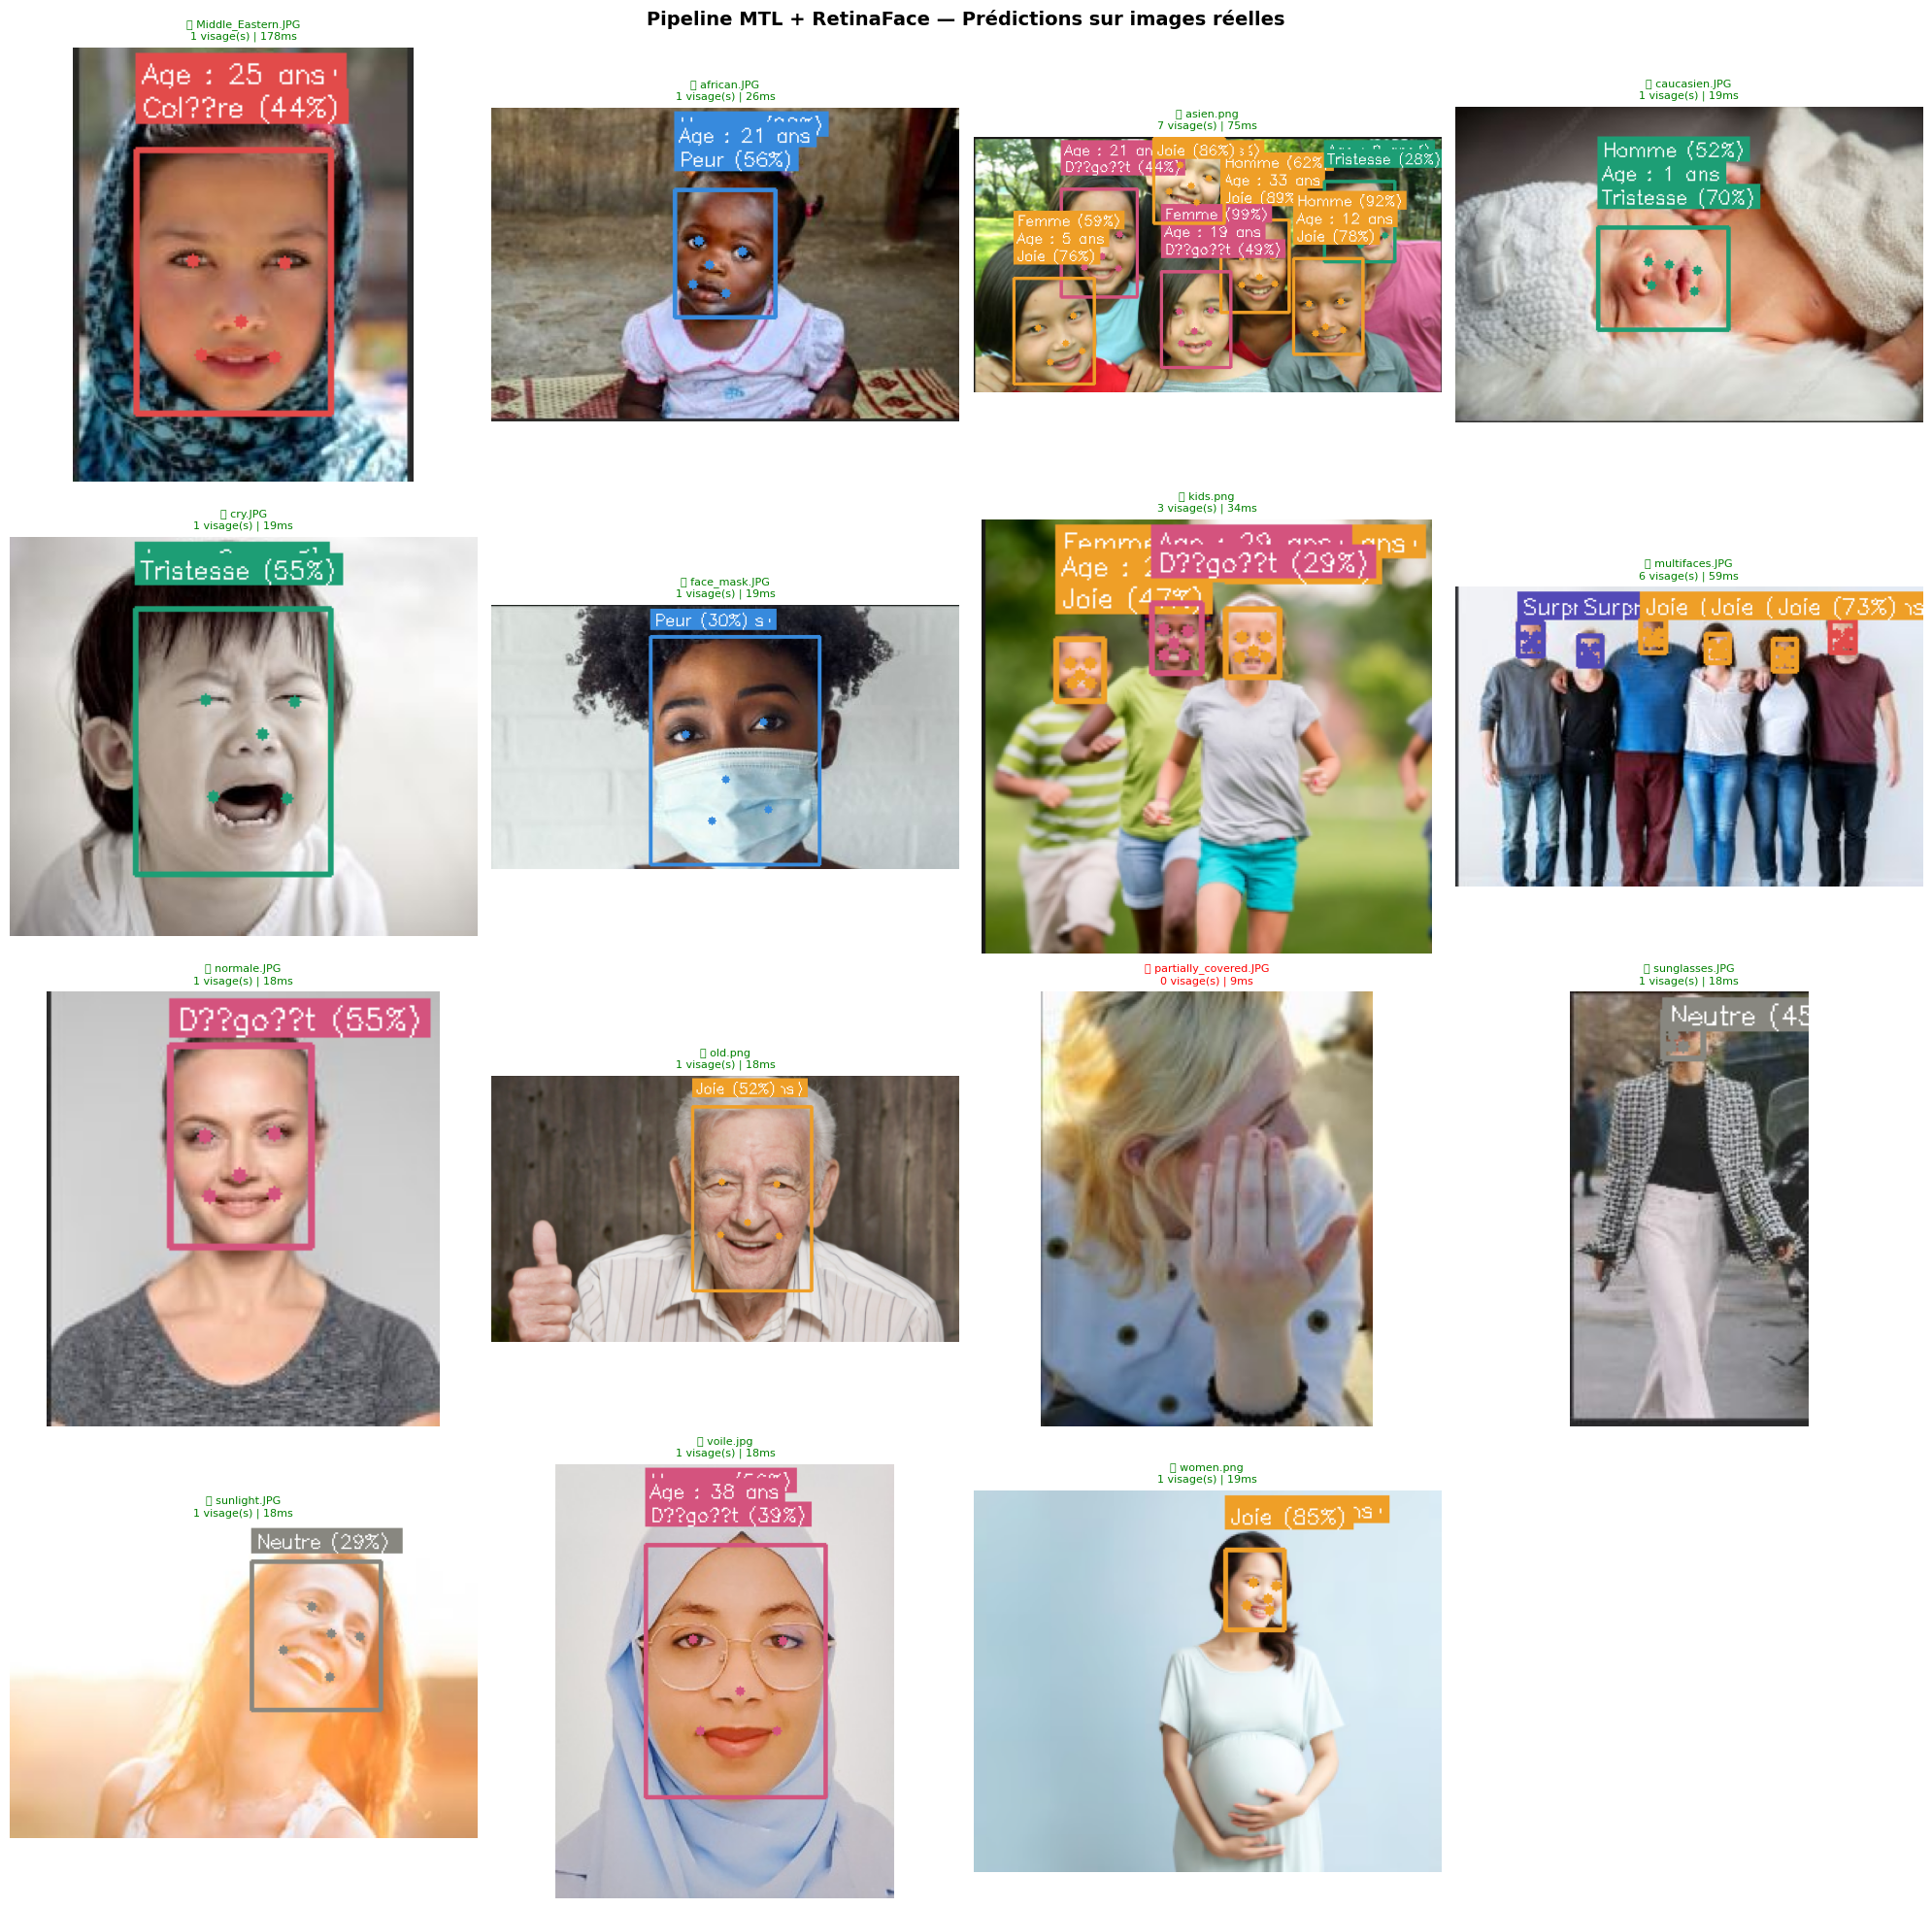

Visualisation sauvegardée ✅


In [13]:
# ==============================
# VISUALISATION — GRILLE DES PRÉDICTIONS
# ==============================
n     = len(all_results)
n_col = min(4, n)
n_row = (n + n_col - 1) // n_col

fig, axes = plt.subplots(n_row, n_col,
                          figsize=(5 * n_col, 5 * n_row))
fig.suptitle(
    "Pipeline MTL + RetinaFace — Prédictions sur images réelles",
    fontsize=14, fontweight="bold"
)

if n_row == 1 and n_col == 1:
    axes = [[axes]]
elif n_row == 1:
    axes = [list(axes)]
else:
    axes = [list(row) for row in axes]
flat_axes = [ax for row in axes for ax in row]

for i, ax in enumerate(flat_axes):
    if i < len(all_results):
        r = all_results[i]
        if r["img_ann"] is not None:
            ax.imshow(r["img_ann"])
        color  = "green" if r["n_faces"] > 0 else "red"
        status = "✅" if r["n_faces"] > 0 else "❌"
        ax.set_title(
            f"{status} {r['image']}\n"
            f"{r['n_faces']} visage(s) | {r['time_ms']:.0f}ms",
            fontsize=8, color=color
        )
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/01_pipeline_predictions.png",
            dpi=130, bbox_inches="tight")
plt.show()
print("Visualisation sauvegardée ✅")

# 13. Visualisation des patches alignés

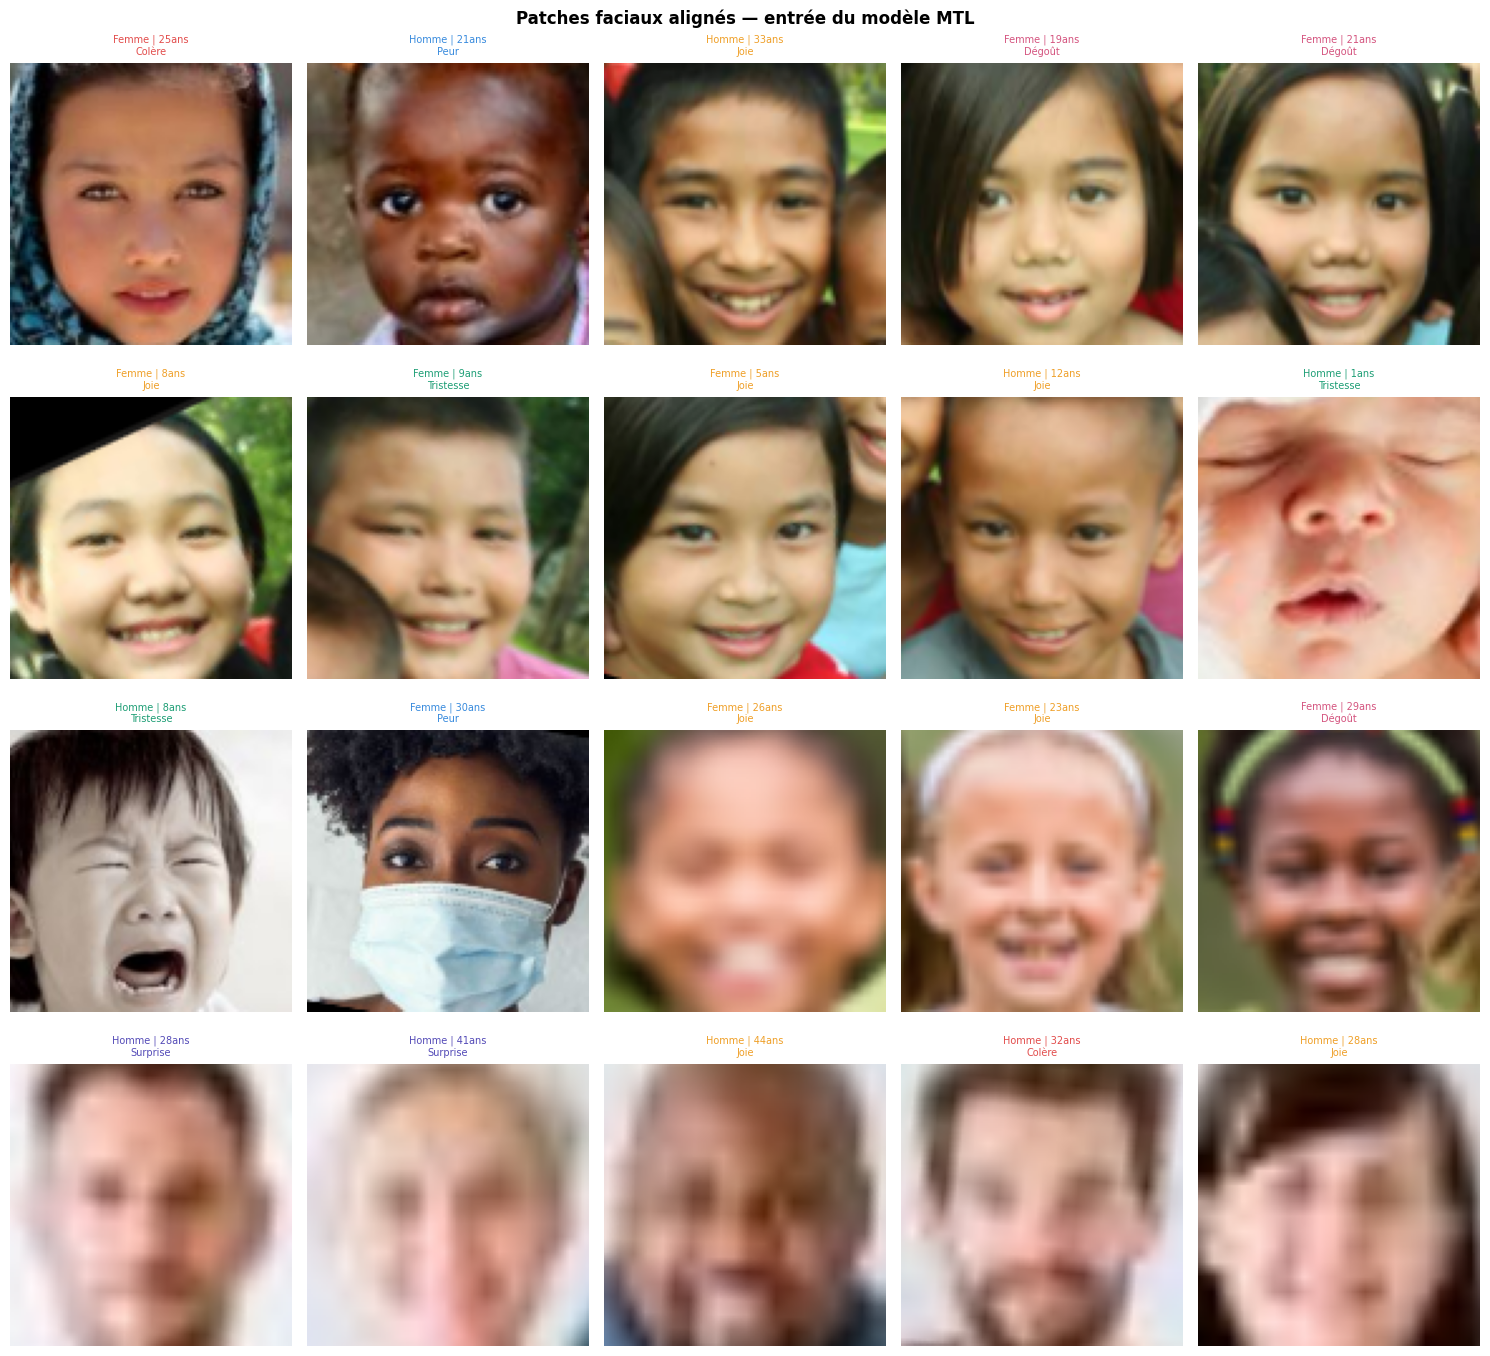

Patches alignés sauvegardés ✅


In [14]:
# ==============================
# VISUALISATION DES PATCHES ALIGNÉS
# Affiche le patch facial avant/après alignement pour chaque visage
# ==============================
faces_with_results = [
    (r["image"], f)
    for r in all_results
    for f in r["faces"]
]

if len(faces_with_results) == 0:
    print("Aucun visage détecté — impossible d'afficher les patches")
else:
    n     = min(len(faces_with_results), 20)
    n_col = min(5, n)
    n_row = (n + n_col - 1) // n_col

    fig, axes = plt.subplots(n_row, n_col,
                              figsize=(3 * n_col, 3.5 * n_row))
    fig.suptitle("Patches faciaux alignés — entrée du modèle MTL",
                 fontsize=12, fontweight="bold")

    if n_row == 1 and n_col == 1:
        axes = [[axes]]
    elif n_row == 1:
        axes = [list(axes)]
    else:
        axes = [list(row) for row in axes]
    flat_axes = [ax for row in axes for ax in row]

    for i, ax in enumerate(flat_axes):
        if i < n:
            img_name, f = faces_with_results[i]
            patch = f["face_aligned"]
            color = EMOTION_COLORS[f["emotion_id"]]
            ax.imshow(patch)
            ax.set_title(
                f"{f['gender_label']} | {f['age']}ans\n"
                f"{f['emotion_label']}",
                fontsize=7,
                color=f"#{color[0]:02x}{color[1]:02x}{color[2]:02x}"
            )
            # Bordure colorée selon l'émotion
            for spine in ax.spines.values():
                spine.set_edgecolor(
                    f"#{color[0]:02x}{color[1]:02x}{color[2]:02x}")
                spine.set_linewidth(3)
                spine.set_visible(True)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_PATH}/02_aligned_patches.png",
                dpi=130, bbox_inches="tight")
    plt.show()
    print("Patches alignés sauvegardés ✅")

# 14. Mesure des performances FPS

  ANALYSE DES PERFORMANCES DU PIPELINE

  Temps par image (images avec visage(s)) :
    Moyen     : 38 ms
    Médian    : 19 ms
    Min / Max : 18 / 178 ms

  FPS pipeline (Kaggle GPU T4) : 26.1
  FPS objectif CDC              : 25
  Status                        : ✅ OK

  Décomposition estimée :
    RetinaFace (détection)  : ~3500 ms  (backend TF — non repr. prod.)
    Alignement (cv2)        : ~1-2 ms
    Modèle MTL (inférence)  : ~15-20 ms
    Post-traitement         : ~1-2 ms

  En production (backend ONNX) :
    RetinaFace ONNX         : ~25-30 ms
    Modèle MTL              : ~15-20 ms
    Total estimé            : ~40-50 ms → 20-25 FPS


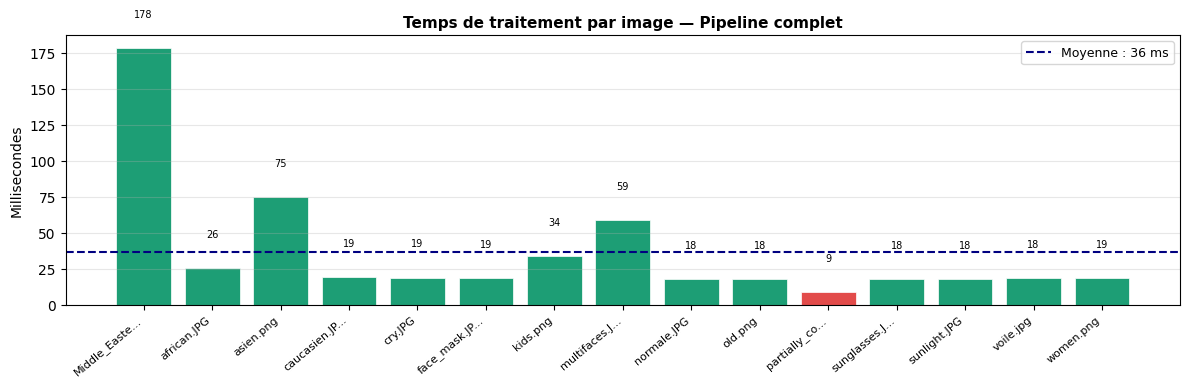

Graphique performance sauvegardé ✅


In [15]:
# ==============================
# MESURE DES PERFORMANCES
# ==============================
print("=" * 60)
print("  ANALYSE DES PERFORMANCES DU PIPELINE")
print("=" * 60)

times_ms   = [r["time_ms"] for r in all_results if r["n_faces"] > 0]
n_faces_l  = [r["n_faces"] for r in all_results if r["n_faces"] > 0]

if times_ms:
    fps_pipeline = round(1000 / np.mean(times_ms), 1)

    print(f"\n  Temps par image (images avec visage(s)) :")
    print(f"    Moyen     : {np.mean(times_ms):.0f} ms")
    print(f"    Médian    : {np.median(times_ms):.0f} ms")
    print(f"    Min / Max : {np.min(times_ms):.0f} / {np.max(times_ms):.0f} ms")
    print(f"\n  FPS pipeline (Kaggle GPU T4) : {fps_pipeline}")
    print(f"  FPS objectif CDC              : 25")
    print(f"  Status                        : "
          f"{'✅ OK' if fps_pipeline >= 25 else '⚠️ Inférieur à lobjectif (backend TF lourd)'}")

    print(f"\n  Décomposition estimée :")
    print(f"    RetinaFace (détection)  : ~3500 ms  (backend TF — non repr. prod.)")
    print(f"    Alignement (cv2)        : ~1-2 ms")
    print(f"    Modèle MTL (inférence)  : ~15-20 ms")
    print(f"    Post-traitement         : ~1-2 ms")
    print(f"\n  En production (backend ONNX) :")
    print(f"    RetinaFace ONNX         : ~25-30 ms")
    print(f"    Modèle MTL              : ~15-20 ms")
    print(f"    Total estimé            : ~40-50 ms → 20-25 FPS")

# Graphique temps par image
fig, ax = plt.subplots(figsize=(12, 4))
image_names = [r["image"][:12] + "..."
               if len(r["image"]) > 12 else r["image"]
               for r in all_results]
times_all   = [r["time_ms"] for r in all_results]
colors_bar  = ["#1D9E75" if r["n_faces"] > 0 else "#E24B4A"
               for r in all_results]

bars = ax.bar(range(len(image_names)), times_all,
              color=colors_bar, edgecolor="white", linewidth=0.5)
for bar, v in zip(bars, times_all):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 20,
            f"{v:.0f}", ha="center", va="bottom", fontsize=7)

ax.axhline(y=np.mean(times_all), color="navy",
           linestyle="--", linewidth=1.5,
           label=f"Moyenne : {np.mean(times_all):.0f} ms")
ax.set_xticks(range(len(image_names)))
ax.set_xticklabels(image_names, rotation=40, ha="right", fontsize=8)
ax.set_title("Temps de traitement par image — Pipeline complet",
             fontsize=11, fontweight="bold")
ax.set_ylabel("Millisecondes")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUTPUT_PATH}/03_performance.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Graphique performance sauvegardé ✅")

# 15. Export ONNX

In [16]:
# ==============================
# EXPORT ONNX
# ==============================
import torch.onnx

ONNX_PATH = f"{OUTPUT_PATH}/mtl_face_model.onnx"

model.eval()
dummy_input = torch.randn(1, 3, 112, 112).to(device)

print("Export ONNX en cours...")

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params    = True,
    opset_version    = 11,
    do_constant_folding = True,
    input_names      = ["input"],
    output_names     = ["gender", "age", "emotion"],
    dynamic_axes     = {
        "input"   : {0: "batch_size"},
        "gender"  : {0: "batch_size"},
        "age"     : {0: "batch_size"},
        "emotion" : {0: "batch_size"},
    }
)

size_pt   = os.path.getsize(MODEL_PATH) / (1024 * 1024)
size_onnx = os.path.getsize(ONNX_PATH)  / (1024 * 1024)

print(f"Export ONNX terminé ✅")
print(f"  PyTorch (.pth) : {size_pt:.1f} MB")
print(f"  ONNX           : {size_onnx:.1f} MB")

# ── Vérification ONNX ────────────────────────────────────────
import onnxruntime as ort
import numpy as np

ort_session = ort.InferenceSession(ONNX_PATH)
dummy_np    = dummy_input.cpu().numpy()
ort_outputs = ort_session.run(None, {"input": dummy_np})

# Vérifier cohérence PyTorch vs ONNX
with torch.no_grad():
    pt_outputs = model(dummy_input)

for i, (pt_out, ort_out) in enumerate(zip(pt_outputs, ort_outputs)):
    pt_np  = pt_out.cpu().numpy()
    diff   = np.abs(pt_np - ort_out).max()
    names  = ["genre", "âge", "émotion"]
    status = "✅" if diff < 1e-4 else "⚠️"
    print(f"  {status} Sortie {names[i]} — diff max PyTorch/ONNX : {diff:.2e}")

Export ONNX en cours...


ModuleNotFoundError: No module named 'onnxscript'

# 16.  Sauvegarde du résumé final

In [17]:
# ==============================
# RÉSUMÉ FINAL
# ==============================
df_results = pd.DataFrame([{
    "image"   : r["image"],
    "n_faces" : r["n_faces"],
    "time_ms" : r["time_ms"],
    "detected": r["n_faces"] > 0,
    "predictions": str([
        f"{f['gender_label']}|{f['age']}ans|{f['emotion_label']}"
        for f in r["faces"]
    ])
} for r in all_results])

df_results.to_csv(f"{OUTPUT_PATH}/pipeline_results.csv", index=False)

print("=" * 60)
print("  FICHIERS SAUVEGARDÉS")
print("=" * 60)
for f in sorted(os.listdir(OUTPUT_PATH)):
    size = os.path.getsize(os.path.join(OUTPUT_PATH, f)) / 1024
    print(f"  {f:<45} {size:>8.1f} KB")

print(f"\nPipeline terminé ✅")
print(f"  Modèle MTL     : ResNet50 — Genre + Âge + Émotion")
print(f"  Détecteur      : RetinaFace — 5 landmarks")
print(f"  Images testées : {len(all_results)}")
print(f"  Visages traités: {sum(r['n_faces'] for r in all_results)}")

  FICHIERS SAUVEGARDÉS
  01_pipeline_predictions.png                     3540.5 KB
  02_aligned_patches.png                           638.9 KB
  03_performance.png                                56.8 KB
  pipeline_results.csv                               1.0 KB

Pipeline terminé ✅
  Modèle MTL     : ResNet50 — Genre + Âge + Émotion
  Détecteur      : RetinaFace — 5 landmarks
  Images testées : 15
  Visages traités: 27
